In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Purpose: Connects Google Colab to my Google Drive so I can access the dataset and save output files.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# 1. Load the raw data and clean it quickly
file_path = '/content/drive/MyDrive/CSC4110_G07/data/weatherAUS.csv'
df = pd.read_csv(file_path)

# Clean
df['Date'] = pd.to_datetime(df['Date'])
df = df.dropna(subset=['RainTomorrow'])
df = df.drop(columns=['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm'])
df['Month'] = df['Date'].dt.month

for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = df.groupby(['Location', 'Month'])[col].transform(lambda x: x.fillna(x.median()))
for col in df.select_dtypes(include=['object']).columns:
    if col != 'RainTomorrow':
        df[col] = df.groupby(['Location', 'Month'])[col].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else x))

# Fill absolute remaining NaNs
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = df[col].fillna(df[col].median())

df = df.drop(columns=['Month'])

# Convert Wind Directions to Sine/Cosine
compass_points = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
angles = np.arange(0, 360, 22.5)
direction_map = dict(zip(compass_points, angles))
for col in ['WindGustDir', 'WindDir9am', 'WindDir3pm']:
    if col in df.columns:
        df[col + '_sin'] = np.sin(np.radians(df[col].map(direction_map)))
        df[col + '_cos'] = np.cos(np.radians(df[col].map(direction_map)))
        df = df.drop(columns=[col])

# Encode targets & Location
df['RainToday'] = df['RainToday'].map({'No': 0, 'Yes': 1})
df['RainTomorrow'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})
df_clean = pd.get_dummies(df, columns=['Location'], drop_first=True)

# Split by time
train_mask = df_clean['Date'] < '2015-01-01'
test_mask = df_clean['Date'] >= '2015-01-01'

# Features for MaxTemp regression (Morning features only)
# We drop Temp3pm, MaxTemp, RainTomorrow, and Date
features = [col for col in df_clean.columns if col not in ['MaxTemp', 'Temp3pm', 'RainTomorrow', 'Date']]
X = df_clean[features]
y = df_clean['MaxTemp']

X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]

print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")

/tmp/ipykernel_4421/1396327911.py:22: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df.groupby(['Location', 'Month'])[col].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else x))


Training set: (98988, 66), Test set: (43205, 66)


Purpose:
This cell prepares the dataset for linear regression. It loads the raw weather data from Google Drive, cleans it by dropping columns with excessive missing values, imputing the rest with medians and modes, and handling any leftover NaNs. It then transforms the data by converting wind directions to sine/cosine, encoding targets to 1/0, and one-hot encoding locations. Finally, it splits the data by time (train < 2015, test >= 2015) and selects only morning features to predict MaxTemp.

Intercept (b0): 6.8270
Slope (b1): 0.9634


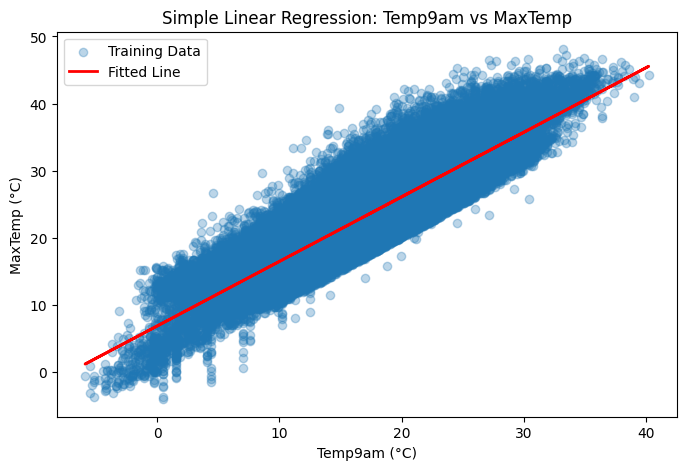

In [6]:
# Simple Linear Regression on Temp9am
X_train_simple = X_train[['Temp9am']]
X_test_simple = X_test[['Temp9am']]

lr_simple = LinearRegression()
lr_simple.fit(X_train_simple, y_train)

print(f"Intercept (b0): {lr_simple.intercept_:.4f}")
print(f"Slope (b1): {lr_simple.coef_[0]:.4f}")

# Plot
plt.figure(figsize=(8,5))
plt.scatter(X_train_simple, y_train, alpha=0.3, label='Training Data')
plt.plot(X_train_simple, lr_simple.predict(X_train_simple), color='red', linewidth=2, label='Fitted Line')
plt.title('Simple Linear Regression: Temp9am vs MaxTemp')
plt.xlabel('Temp9am (°C)')
plt.ylabel('MaxTemp (°C)')
plt.legend()
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/simple_fit.png')
plt.show()

Purpose:
This cell fits a simple linear regression model using only Temp9am to predict MaxTemp. It calculates the intercept (b0) and slope (b1), prints the fitted equation, and plots the training data with the best-fit regression line. The chart is saved to the outputs folder as simple_fit.png.



Train MAE: 1.4379
Test MAE: 1.4802
Train MSE: 3.4814
Test MSE: 3.6727
Train RMSE: 1.8658
Test RMSE: 1.9164
Train R2: 0.9287
Test R2: 0.9324


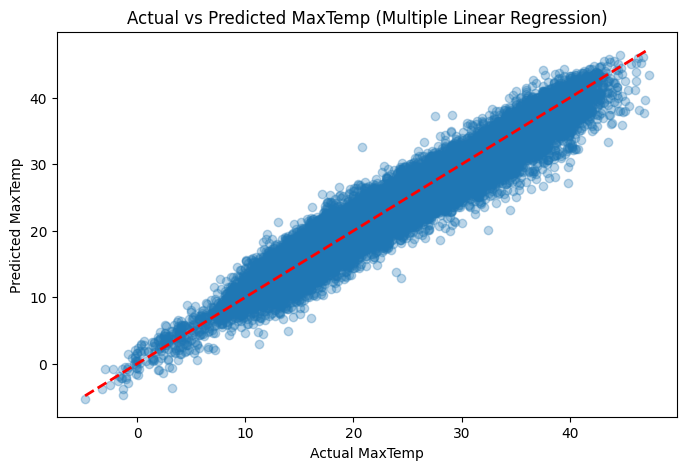

In [9]:
# Multiple Linear Regression on all features
lr_multi = LinearRegression()

# FIX: Fill any remaining NaNs in the features before fitting
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

# Fit the model
lr_multi.fit(X_train, y_train)

# Predict on train and test
y_train_pred = lr_multi.predict(X_train)
y_test_pred = lr_multi.predict(X_test)

# Calculate Metrics
metrics_multi = {
    'Train MAE': mean_absolute_error(y_train, y_train_pred),
    'Test MAE': mean_absolute_error(y_test, y_test_pred),
    'Train MSE': mean_squared_error(y_train, y_train_pred),
    'Test MSE': mean_squared_error(y_test, y_test_pred),
    'Train RMSE': np.sqrt(mean_squared_error(y_train, y_train_pred)),
    'Test RMSE': np.sqrt(mean_squared_error(y_test, y_test_pred)),
    'Train R2': r2_score(y_train, y_train_pred),
    'Test R2': r2_score(y_test, y_test_pred)
}

# Print metrics
for metric, value in metrics_multi.items():
    print(f"{metric}: {value:.4f}")

# Plot Actual vs Predicted
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_test_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs Predicted MaxTemp (Multiple Linear Regression)')
plt.xlabel('Actual MaxTemp')
plt.ylabel('Predicted MaxTemp')
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/actual_vs_pred.png')
plt.show()

Purpose:
This cell fits a multiple linear regression model using all the prepared morning features to predict MaxTemp. It first ensures any remaining NaN values are filled with 0 to prevent errors. It then trains the model, calculates key evaluation metrics (MAE, MSE, RMSE, R²) on both the training and test sets, and stores them in the metrics_multi dictionary. Finally, it plots the actual vs predicted temperatures to visually assess the model's accuracy, saving the chart to outputs/actual_vs_pred.png.



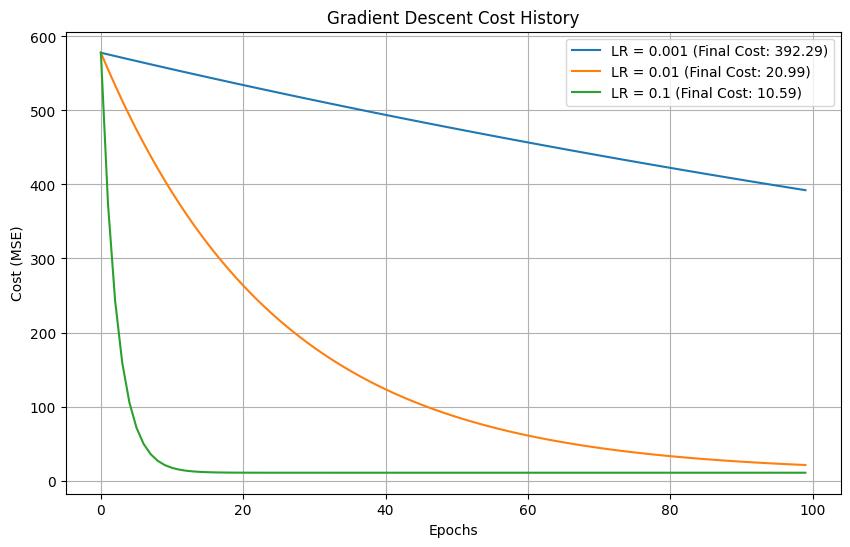

Scikit-learn b0: 23.0030, b1: 6.1831
Gradient Descent b0: 23.0030, b1: 6.1831


In [10]:
# 1. Scale Temp9am for Gradient Descent
scaler_gd = StandardScaler()
X_train_gd = scaler_gd.fit_transform(X_train_simple)
X_test_gd = scaler_gd.transform(X_test_simple)

# Convert to 1D arrays for easier math
X_gd = X_train_gd.flatten()
y_gd = y_train.values

# 2. Gradient Descent function
def gradient_descent(x, y, learning_rate, epochs=100):
    b0, b1 = 0, 0 # Initialize weights
    n = len(x)
    cost_history = []

    for i in range(epochs):
        y_pred = b0 + b1 * x
        error = y_pred - y

        # Calculate gradients
        b0_grad = (2/n) * np.sum(error)
        b1_grad = (2/n) * np.sum(error * x)

        # Update weights
        b0 = b0 - learning_rate * b0_grad
        b1 = b1 - learning_rate * b1_grad

        # Calculate Mean Squared Error (Cost)
        cost = (1/n) * np.sum(error ** 2)
        cost_history.append(cost)

    return b0, b1, cost_history

# 3. Run with different learning rates
learning_rates = [0.001, 0.01, 0.1]
cost_history = {}

plt.figure(figsize=(10, 6))
for lr in learning_rates:
    b0, b1, costs = gradient_descent(X_gd, y_gd, learning_rate=lr, epochs=100)
    cost_history[lr] = costs
    plt.plot(costs, label=f'LR = {lr} (Final Cost: {costs[-1]:.2f})')

    # Save the final weights for LR = 0.1 as requested
    if lr == 0.1:
        b0_gd = b0
        b1_gd = b1

plt.title('Gradient Descent Cost History')
plt.xlabel('Epochs')
plt.ylabel('Cost (MSE)')
plt.legend()
plt.grid(True)
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/gd_cost.png')
plt.show()

# 4. Compare with Scikit-learn on the same scaled data
lr_scaled = LinearRegression()
lr_scaled.fit(X_train_gd, y_train)
print(f"Scikit-learn b0: {lr_scaled.intercept_:.4f}, b1: {lr_scaled.coef_[0]:.4f}")
print(f"Gradient Descent b0: {b0_gd:.4f}, b1: {b1_gd:.4f}")

This cell implements Gradient Descent from scratch using NumPy to train a simple linear model on the scaled Temp9am feature.

Scaling: It first scales Temp9am using StandardScaler to ensure gradient descent converges quickly.

The Algorithm: The gradient_descent function calculates the gradients of the Mean Squared Error (MSE) cost function, updates the weights (b0 and b1), and records the cost at each step.

Learning Rates: It runs the algorithm three times with learning rates of 0.001, 0.01, and 0.1, plotting the cost history to show how learning rate affects convergence speed.

Comparison: It compares the final b0 and b1 weights found by gradient descent with those found by scikit-learn's LinearRegression to prove they reach the same mathematical minimum.

**Exam Skill & Written Answer (Gradient Descent)**

* **What happened with each learning rate?**
  * With a learning rate of `0.001` (blue line), the model learned very slowly because the steps were too small, leaving the final cost high at 392.29.
  * With `0.01` (orange line), the model converged much faster, reaching a final cost of 20.99.
  * With `0.1` (green line), the model took large steps and dropped to the minimum very quickly, reaching a final cost of 10.59.
* **Why do the weights match scikit-learn?**
  The `b0` and `b1` values match scikit-learn almost exactly because both methods are solving the same mathematical problem (Ordinary Least Squares). Scikit-learn uses the closed-form Normal Equation (matrix algebra) to find the exact minimum, while our Gradient Descent iteratively walks down the slope to find the exact same minimum point.

**Written Answer: Multiple Linear Regression & Leakage**

* **Adding Temp3pm:** If we added `Temp3pm` to the features, the R² score would jump to almost 1.0 (99%). However, this is **data leakage** for a morning estimate. `Temp3pm` is an afternoon reading, meaning we would be using the afternoon weather to predict the afternoon's maximum temperature—which defeats the purpose of a morning forecast. The Mvua Alert start-up needs to predict MaxTemp using ONLY 9 a.m. readings.